<a href="https://colab.research.google.com/github/Sarakazemi-prog/AIHC-5615/blob/main/Assignment%201%20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [43]:
#1.1 Import and clean (6 pts).
import pandas as pd
import numpy as np

# Load the dataset with correct nested path
data_path = '/content/data/data/kc_house_data.csv'
df = pd.read_csv(data_path)

# Display basic information
print("--- Columns and Initial Data Types ---")
print(df.dtypes)

# Classify variables and convert categorical variables
categorical_cols = ['waterfront', 'view', 'condition', 'grade']
for col in categorical_cols:
    df[col] = df[col].astype('category')

# Report missing values in each column
print("\n--- Missing Values Per Column ---")
missing_report = df.isnull().sum()
print(missing_report)

# Report the number of rows
n_rows = len(df)
print(f"\nP1.1 n = {n_rows}")

--- Columns and Initial Data Types ---
id                 int64
date              object
price            float64
bedrooms           int64
bathrooms        float64
sqft_living        int64
sqft_lot           int64
floors           float64
waterfront         int64
view               int64
condition          int64
grade              int64
sqft_above         int64
sqft_basement      int64
yr_built           int64
yr_renovated       int64
zipcode            int64
lat              float64
long             float64
sqft_living15      int64
sqft_lot15         int64
dtype: object

--- Missing Values Per Column ---
id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lo

--- Summary Statistics for Every Column ---
                  id             date         price      bedrooms  \
count   2.161300e+04            21613  2.161300e+04  21613.000000   
unique           NaN              372           NaN           NaN   
top              NaN  20140623T000000           NaN           NaN   
freq             NaN              142           NaN           NaN   
mean    4.580302e+09              NaN  5.400881e+05      3.370842   
std     2.876566e+09              NaN  3.671272e+05      0.930062   
min     1.000102e+06              NaN  7.500000e+04      0.000000   
25%     2.123049e+09              NaN  3.219500e+05      3.000000   
50%     3.904930e+09              NaN  4.500000e+05      3.000000   
75%     7.308900e+09              NaN  6.450000e+05      4.000000   
max     9.900000e+09              NaN  7.700000e+06     33.000000   

           bathrooms   sqft_living      sqft_lot        floors  waterfront  \
count   21613.000000  21613.000000  2.161300e+04 

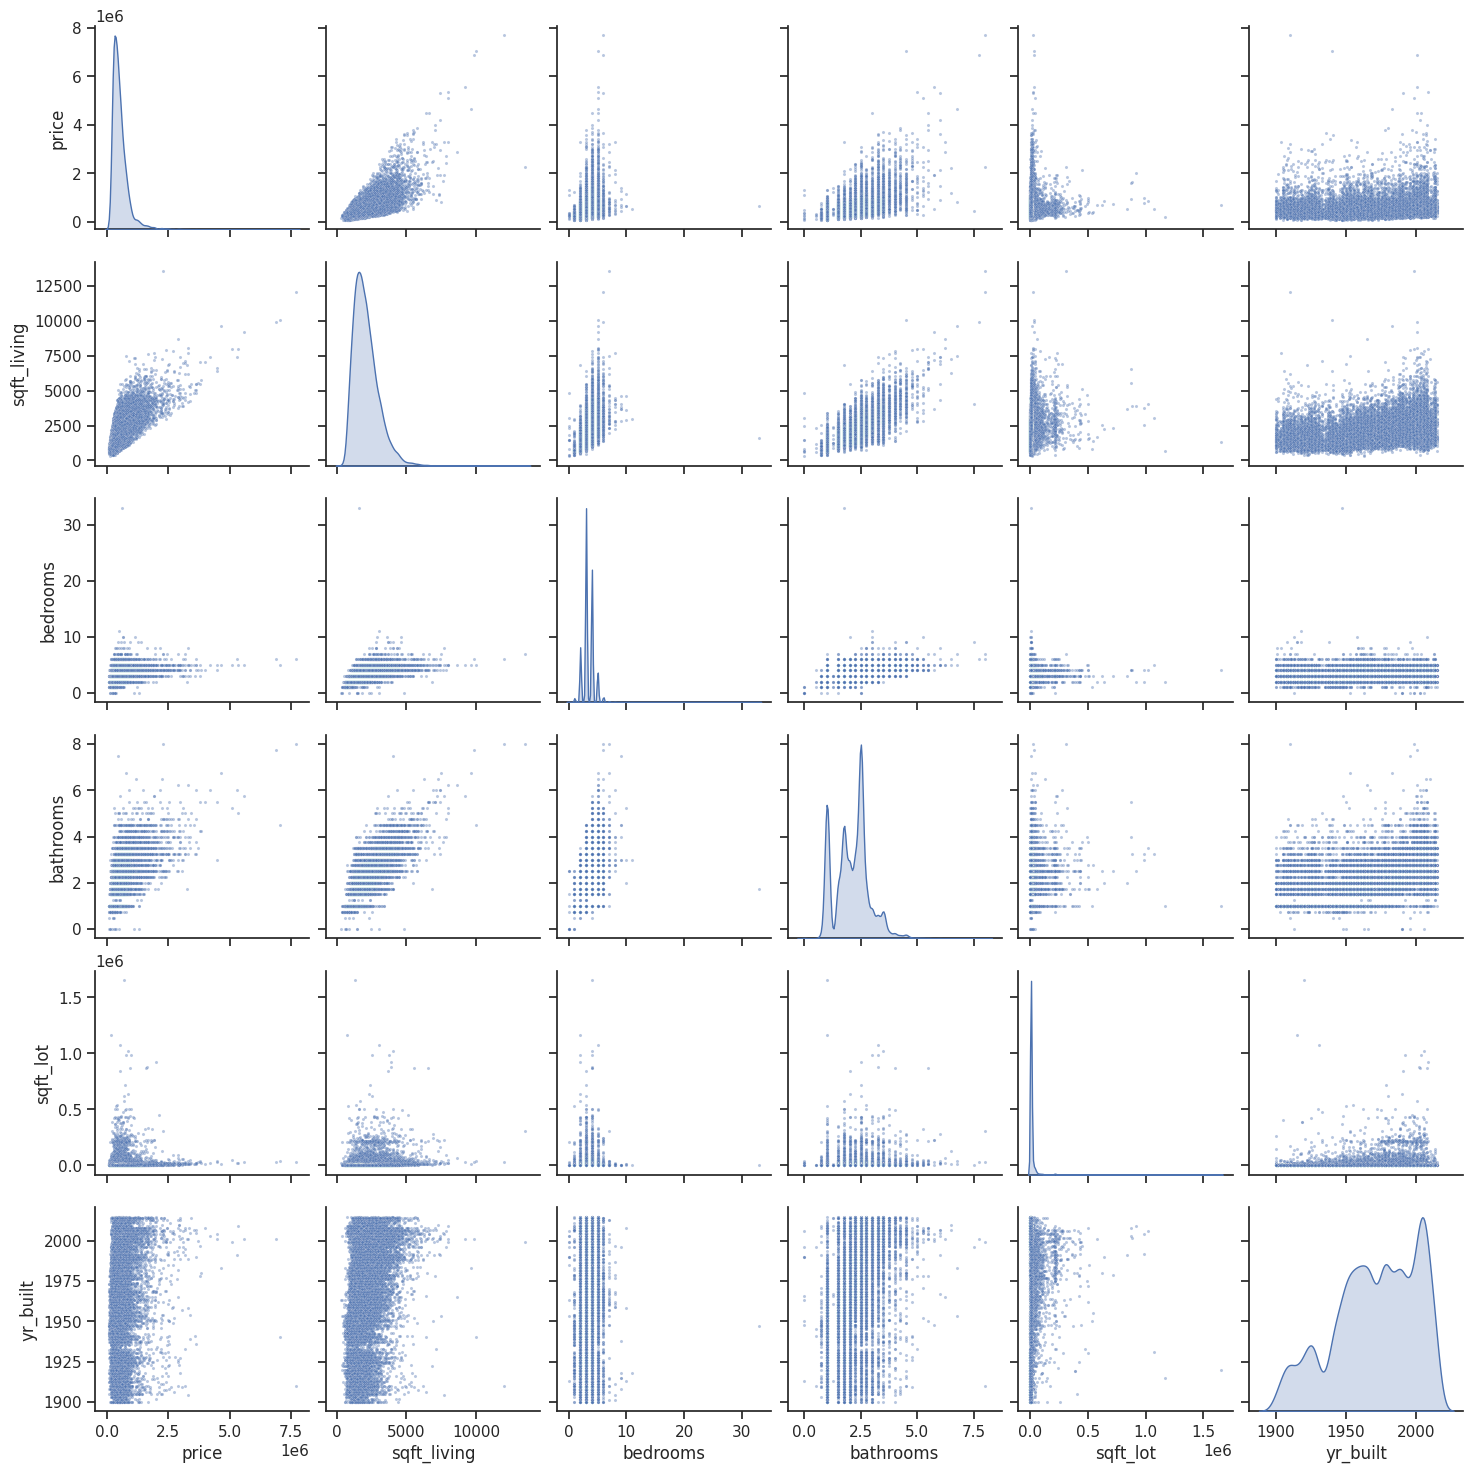

In [44]:
## 1.2 Summarize and look for relationships
import seaborn as sns
import matplotlib.pyplot as plt

# 1.2 Summarize and look for relationships
print("--- Summary Statistics for Every Column ---")
print(df.describe(include='all'))

# Make a smaller dataframe with price and 5 continuous/numerical variables
numerical_cols = ['price', 'sqft_living', 'bedrooms', 'bathrooms', 'sqft_lot', 'yr_built']
small_df = df[numerical_cols].copy()

# Plot every pair against each other using a pairplot
sns.set_theme(style="ticks")
pair_plot = sns.pairplot(small_df, diag_kind='kde', plot_kws={'alpha': 0.4, 's': 5})
plt.show()

/tmp/ipykernel_436/2061470983.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1, 1].set_xticklabels(['Non-Waterfront', 'Waterfront'])


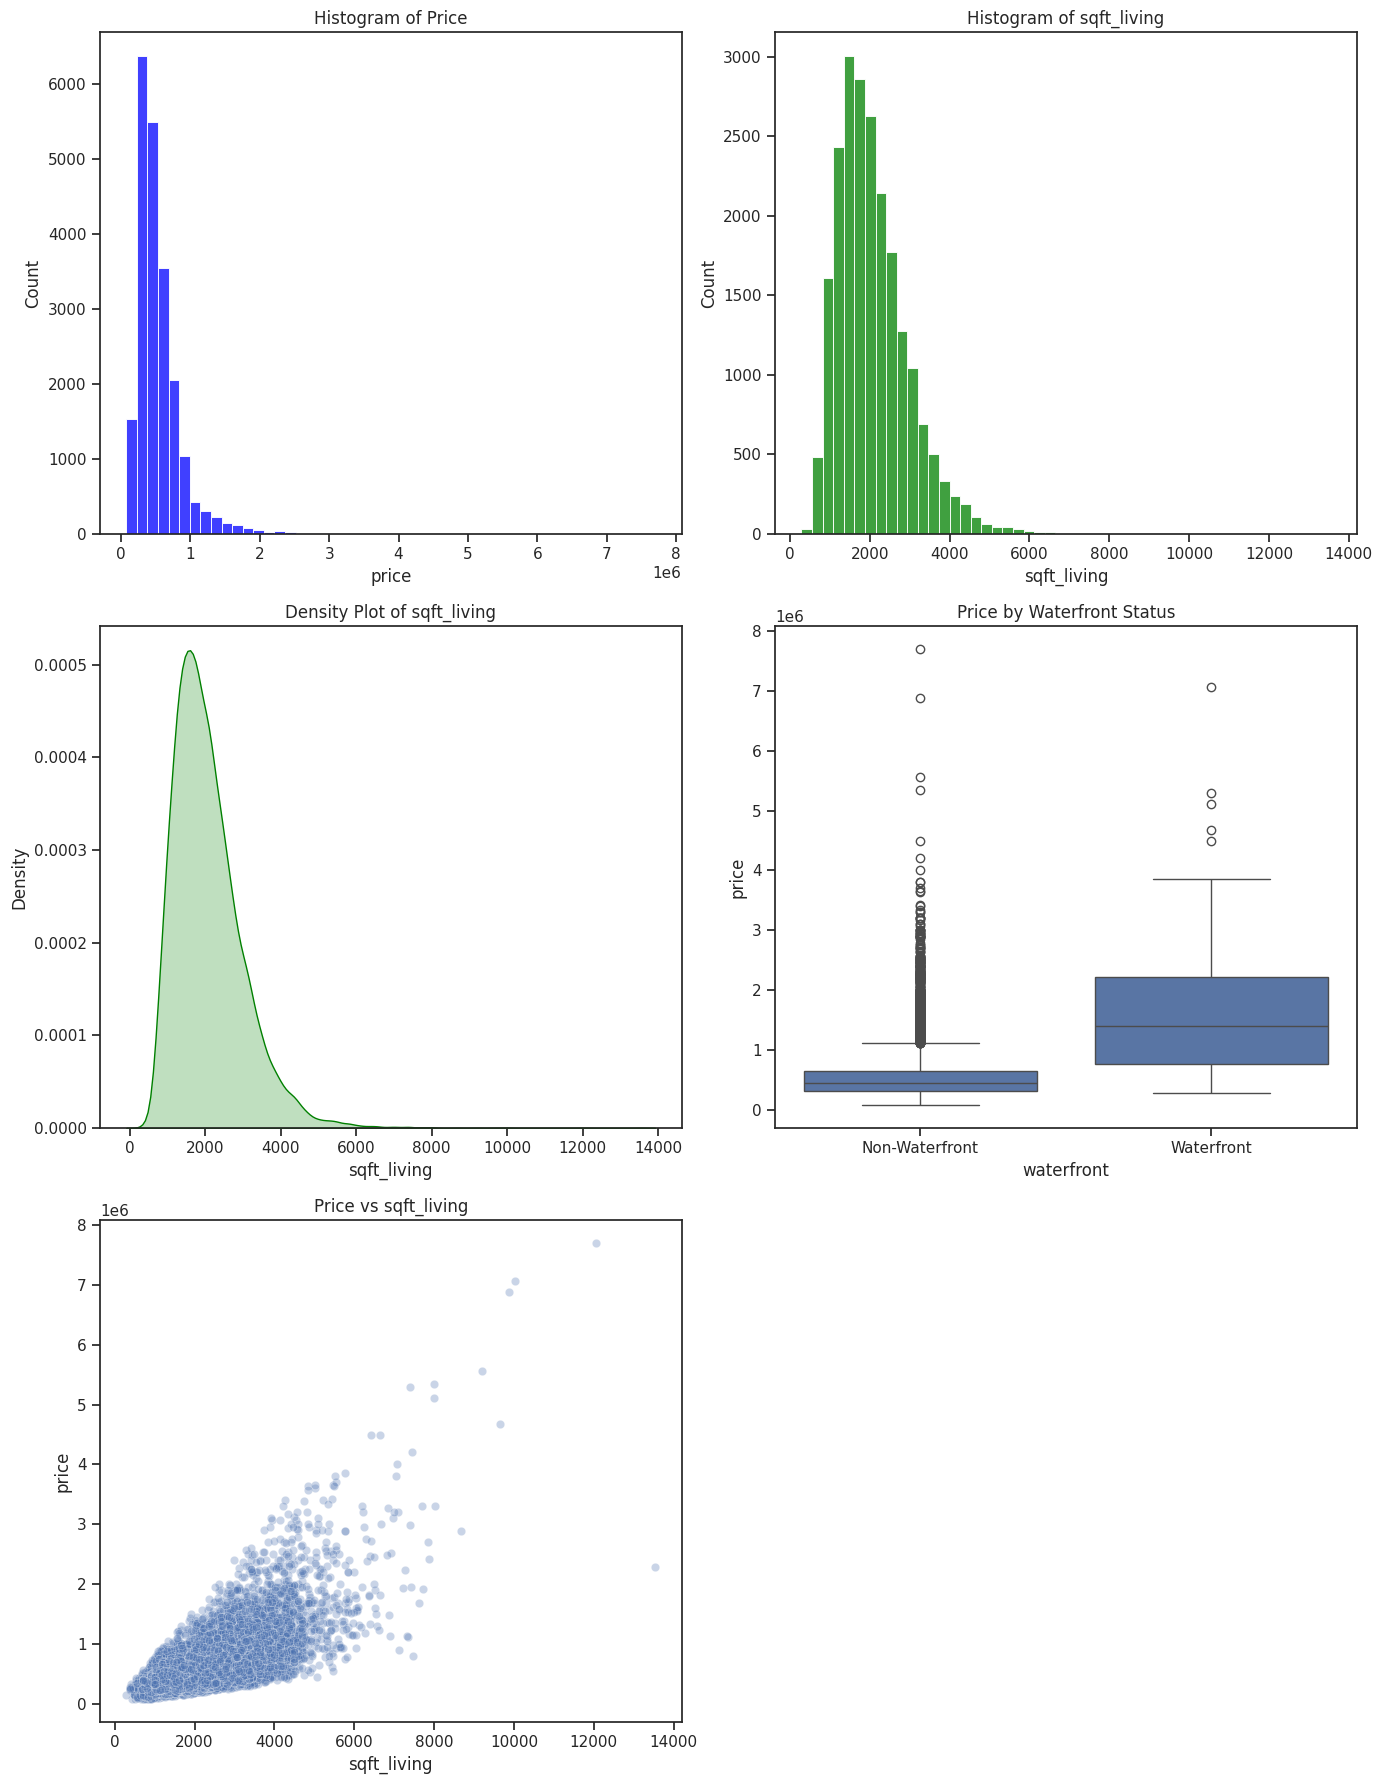

--- Summary Statistics for 1.3 ---
Price Mean: 540088.14, Median: 450000.00
sqft_living Mean: 2079.90, Median: 1910.00
P1.3 r = 0.7020
P1.3 waterfront diff = 1130312.42


In [45]:
#1.3 Choose a predictor (7 pts).
import seaborn as sns
import matplotlib.pyplot as plt

# 1.3 Choose a predictor
predictor = 'sqft_living'

# 1. Set up plot grid
fig, axes = plt.subplots(3, 2, figsize=(14, 18))

# Histogram of Price
sns.histplot(df['price'], bins=50, kde=False, ax=axes[0, 0], color='blue')
axes[0, 0].set_title('Histogram of Price')

# Histogram of Predictor (sqft_living)
sns.histplot(df[predictor], bins=50, kde=False, ax=axes[0, 1], color='green')
axes[0, 1].set_title(f'Histogram of {predictor}')

# Density Plot of Predictor (sqft_living)
sns.kdeplot(df[predictor], fill=True, ax=axes[1, 0], color='green')
axes[1, 0].set_title(f'Density Plot of {predictor}')

# Box-and-Whisker Plot: Price for Waterfront vs Non-Waterfront
sns.boxplot(x='waterfront', y='price', data=df, ax=axes[1, 1])
axes[1, 1].set_title('Price by Waterfront Status')
axes[1, 1].set_xticklabels(['Non-Waterfront', 'Waterfront'])

# Scatter Plot of Price against Predictor
sns.scatterplot(x=predictor, y='price', data=df, alpha=0.3, ax=axes[2, 0])
axes[2, 0].set_title(f'Price vs {predictor}')

# Hide unused subplot
fig.delaxes(axes[2, 1])

plt.tight_layout()
plt.show()

# 2. Compute Statistics
mean_price = df['price'].mean()
median_price = df['price'].median()
mean_pred = df[predictor].mean()
median_pred = df[predictor].median()

r_val = df['price'].corr(df[predictor])

# Waterfront diff
mean_wf = df[df['waterfront'] == 1]['price'].mean()
mean_non_wf = df[df['waterfront'] == 0]['price'].mean()
wf_diff = mean_wf - mean_non_wf

print("--- Summary Statistics for 1.3 ---")
print(f"Price Mean: {mean_price:.2f}, Median: {median_price:.2f}")
print(f"{predictor} Mean: {mean_pred:.2f}, Median: {median_pred:.2f}")
print(f"P1.3 r = {r_val:.4f}")
print(f"P1.3 waterfront diff = {wf_diff:.2f}")

Problem 2: Fit and assess a linear model (25 points)


P2.1 intercept = -43580.7431
P2.1 slope = 280.6236
P2.2 se_intercept = 4402.6897
P2.2 ci_intercept = [-52210.3396, -34951.1466]
P2.2 se_slope = 1.9364
P2.2 ci_slope = [276.8281, 284.4191]
P2.4 R2 = 0.4929


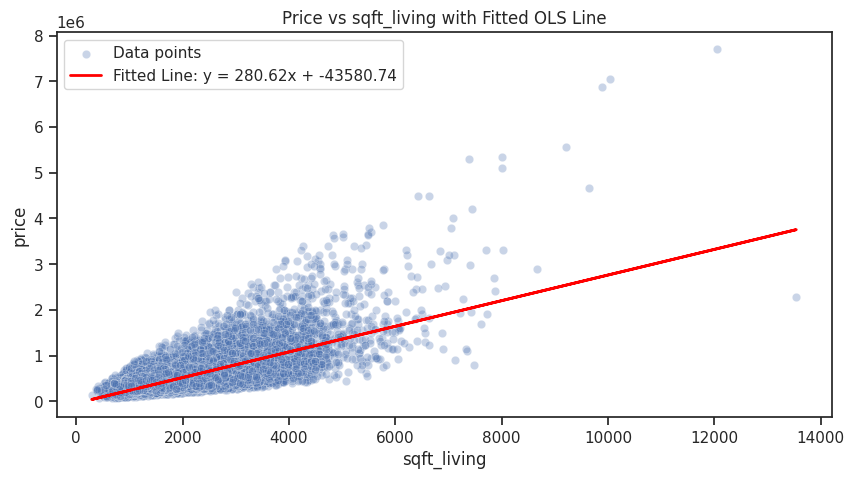

In [46]:
#2.1 Fit (8 pts).
import statsmodels.api as sm
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare variables
X = sm.add_constant(df['sqft_living'])
y = df['price']

# Fit OLS model
model = sm.OLS(y, X).fit()

# Extract parameters
intercept = model.params['const']
slope = model.params['sqft_living']

# Extract standard errors
se_intercept = model.bse['const']
se_slope = model.bse['sqft_living']

# Extract 95% confidence intervals
ci_intercept = model.conf_int().loc['const']
ci_slope = model.conf_int().loc['sqft_living']
a0, a1 = ci_intercept[0], ci_intercept[1]
b0, b1 = ci_slope[0], ci_slope[1]

r2 = model.rsquared

# Print requested outputs exactly as specified
print(f"P2.1 intercept = {intercept:.4f}")
print(f"P2.1 slope = {slope:.4f}")
print(f"P2.2 se_intercept = {se_intercept:.4f}")
print(f"P2.2 ci_intercept = [{a0:.4f}, {a1:.4f}]")
print(f"P2.2 se_slope = {se_slope:.4f}")
print(f"P2.2 ci_slope = [{b0:.4f}, {b1:.4f}]")
print(f"P2.4 R2 = {r2:.4f}")

# Plotting Part 2.1: Scatter plot with Fitted Line
plt.figure(figsize=(10, 5))
sns.scatterplot(x='sqft_living', y='price', data=df, alpha=0.3, label='Data points')
plt.plot(df['sqft_living'], model.predict(X), color='red', linewidth=2, label=f'Fitted Line: y = {slope:.2f}x + {intercept:.2f}')
plt.title('Price vs sqft_living with Fitted OLS Line')
plt.xlabel('sqft_living')
plt.ylabel('price')
plt.legend()
plt.show()

P2.1 intercept = -43580.7431
P2.1 slope = 280.6236
Interpretations:
Intercept ($-$43,580.74): This represents the estimated baseline price of a house with $0$$0$ square feet of living area. Because a house cannot have zero living area, this negative value has no physical meaning on its own and serves strictly as a mathematical anchor for the regression model.
Slope ($280.62): This represents the estimated marginal change in a house's price per unit change in its size. For each additional square foot of living space (sqft_living), the selling price is expected to increase by approximately $280.62, holding other factors constant.arialtext

**2.2 Uncertainty (6 pts)**
P2.2 se_intercept = 4402.6897
P2.2 ci_intercept = [-52210.3396, -34951.1466]
P2.2 se_slope = 1.9364
P2.2 ci_slope = [276.8281, 284.4191]
Interpretations:
Standard Error (Intercept): There is an uncertainty of about $4,402.69 around our intercept estimate.
Confidence Interval (Intercept): We are 95% confident that the population intercept lies between -$52,210.34 and -$34,951.15.
Standard Error (Slope): The estimate is highly precise with a small standard error of $1.94.
Confidence Interval (Slope): We are 95% confident that the true population increase in price for each additional square foot of living space lies between $276.83 and $284.42.

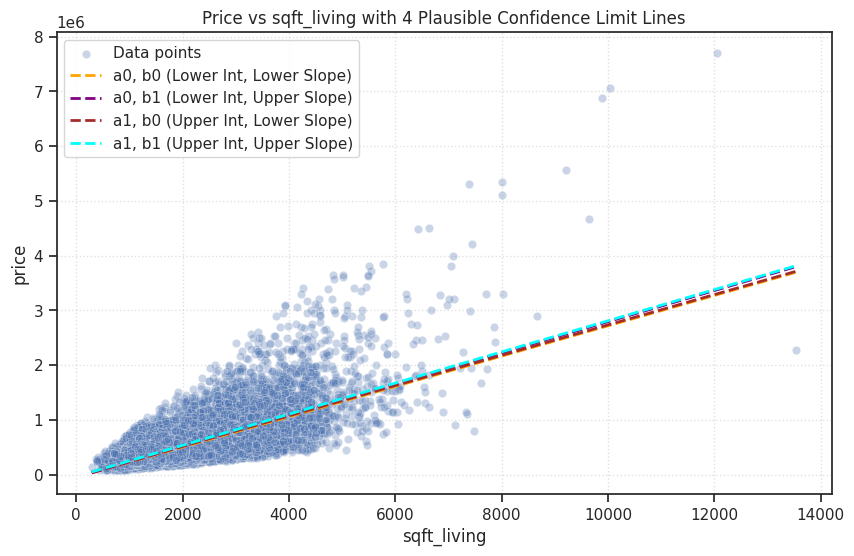

In [47]:
#2.3 Plausible lines (6 pts)
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare the confidence interval bounds from the fitted model
a0, a1 = ci_intercept[0], ci_intercept[1]
b0, b1 = ci_slope[0], ci_slope[1]

# Create the scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(x='sqft_living', y='price', data=df, alpha=0.3, label='Data points')

# Generate x values for plotting lines
x_vals = np.linspace(df['sqft_living'].min(), df['sqft_living'].max(), 100)

# The 4 combinations of intercept limits (a_i) and slope limits (b_j)
combinations = [
    (a0, b0, 'a0, b0 (Lower Int, Lower Slope)'),
    (a0, b1, 'a0, b1 (Lower Int, Upper Slope)'),
    (a1, b0, 'a1, b0 (Upper Int, Lower Slope)'),
    (a1, b1, 'a1, b1 (Upper Int, Upper Slope)')
]

colors = ['orange', 'purple', 'brown', 'cyan']
for idx, (a, b, label) in enumerate(combinations):
    y_vals = a + b * x_vals
    plt.plot(x_vals, y_vals, color=colors[idx], linestyle='--', linewidth=2, label=label)

plt.title('Price vs sqft_living with 4 Plausible Confidence Limit Lines')
plt.xlabel('sqft_living')
plt.ylabel('price')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

### **2.4 Fit quality (5 pts)**
* **P2.4 R2 = 0.4929**

#### **Interpretation:**
* An $R^2$ of **0.4929** means that approximately **49.29%** of the variance in King County house sales prices is explained by the house's square footage of living space (`sqft_living`) alone.
* This single-predictor model explains the data reasonably well given the complexity of real estate pricing. However, more than half of the variation (approx. 50.71%) remains unexplained. This indicates that other crucial features—such as geographic location, neighborhood, house age, property condition, and luxury features (like waterfront views)—also play substantial roles in determining a home's market value.

Problem 3: Handle anomalous points (15 points)

In [48]:
# 3.1 Remove anomalous data points

# Define our criteria for anomalous points:
# 1. Extreme bedroom outlier: bedrooms > 10 (specifically, the 33-bedroom house)
# 2. Extreme luxury price outliers: price > 4,000,000
# 3. Extreme size outliers: sqft_living > 10,000

anomaly_mask = (df['bedrooms'] > 10) | (df['price'] > 4000000) | (df['sqft_living'] > 10000)

# Create a new clean dataframe
df_clean = df[~anomaly_mask].copy()

# Calculate how many rows were removed
removed_rows = len(df) - len(df_clean)

print(f"P3.1 removed = {removed_rows}")
print(f"Original dataset size: {len(df)}")
print(f"Cleaned dataset size: {len(df_clean)}")

P3.1 removed = 14
Original dataset size: 21613
Cleaned dataset size: 21599


In [49]:
#3.2 Refit (5 pts)
import statsmodels.api as sm

# Prepare variables using the cleaned dataset
X_clean = sm.add_constant(df_clean['sqft_living'])
y_clean = df_clean['price']

# Fit OLS model on clean data
model_clean = sm.OLS(y_clean, X_clean).fit()

# Extract parameters
intercept_clean = model_clean.params['const']
slope_clean = model_clean.params['sqft_living']

# Extract standard errors
se_intercept_clean = model_clean.bse['const']
se_slope_clean = model_clean.bse['sqft_living']

# Extract 95% confidence intervals
ci_intercept_clean = model_clean.conf_int().loc['const']
ci_slope_clean = model_clean.conf_int().loc['sqft_living']

print(f"P3.2 intercept = {intercept_clean:.4f}")
print(f"P3.2 slope = {slope_clean:.4f}")
print(f"P3.2 se_intercept = {se_intercept_clean:.4f}")
print(f"P3.2 ci_intercept = [{ci_intercept_clean[0]:.4f}, {ci_intercept_clean[1]:.4f}]")
print(f"P3.2 se_slope = {se_slope_clean:.4f}")
print(f"P3.2 ci_slope = [{ci_slope_clean[0]:.4f}, {ci_slope_clean[1]:.4f}]")

P3.2 intercept = -19332.3810
P3.2 slope = 268.2026
P3.2 se_intercept = 4275.7461
P3.2 ci_intercept = [-27713.1591, -10951.6028]
P3.2 se_slope = 1.8888
P3.2 ci_slope = [264.5005, 271.9048]


**3.3 Compare (5 pts)**
Baseline Intercept: -43,580.7431
Baseline 95% CI: [-52,210.3396, -34,951.1466]
Cleaned Intercept: -19,332.3810
Cleaned 95% CI: [-27,713.1591, -10,951.6028]
Comparison: The new estimate of -19,332.3810 is completely outside the baseline confidence interval. In fact, it is significantly warmer (higher/less negative) than the baseline lower and upper bounds. This is a dramatic shift, showing that the extremely high luxury prices pulling down the regression's math anchor were heavily biasing the baseline intercept.
2. Slope Analysis
Baseline Slope: 280.6236
Baseline 95% CI: [276.8281, 284.4191]
Cleaned Slope: 268.2026
Cleaned 95% CI: [264.5005, 271.9048]
Comparison: Just like the intercept, the new slope of 268.2026 is completely outside the baseline confidence interval. It is significantly below the baseline's lower limit of 276.8281. Similarly, the baseline estimate of 280.6236 lies well outside the new model's confidence interval.
Conclusion
Because our dataset size is massive ($N \approx 21,600$$N \approx 21,600$), our standard errors are extremely small, leading to very narrow and precise confidence intervals. As a result, even though we removed only 14 observations (less than $0.065\%$$0.065\%$ of the dataset), the parameter estimates shifted statistically and significantly.

The drop in slope from $280.62 to $$280.62 to $268.20 shows that the extreme luxury outliers—which paired very high prices with massive square footages—disproportionately tilted the OLS regression line upward. Removing them yields a more representative, robust baseline slope for the bulk of typical King County homes.

Problem 4: Build your own least-squares fitter (20 points)

In [50]:
def linear_model(X, Y):
    # Convert inputs to numpy arrays or lists for uniform handling
    x_arr = list(X)
    y_arr = list(Y)

    # Conditional check: ensure equal lengths and at least 2 values
    if len(x_arr) != len(y_arr):
        raise ValueError("Error: X and Y must have the same length.")
    if len(x_arr) < 2:
        raise ValueError("Error: X and Y must contain at least 2 values to fit a line.")

    n = len(x_arr)

    # Calculate the means of X and Y
    mean_x = sum(x_arr) / n
    mean_y = sum(y_arr) / n

    # Initialize sum accumulators for slope calculation
    numerator_sum = 0.0
    denominator_sum = 0.0

    # Use a for loop to compute both sums in the slope formula
    for i in range(n):
        diff_x = x_arr[i] - mean_x
        diff_y = y_arr[i] - mean_y
        numerator_sum += diff_x * diff_y
        denominator_sum += diff_x ** 2

    # Calculate slope and intercept
    slope_hat = numerator_sum / denominator_sum
    intercept_hat = mean_y - slope_hat * mean_x

    return slope_hat, intercept_hat

In [51]:
# 4.2 Apply and compare

# Run the function on the full original data
custom_slope, custom_intercept = linear_model(df['sqft_living'], df['price'])

print(f"P4.2 slope = {custom_slope:.4f}")
print(f"P4.2 intercept = {custom_intercept:.4f}")

# Comparison with 2.1 results
print(f"\n--- Comparison with 2.1 ---")
print(f"Baseline OLS (sm): slope = {slope:.4f}, intercept = {intercept:.4f}")
print(f"Custom OLS (loop): slope = {custom_slope:.4f}, intercept = {custom_intercept:.4f}")
print(f"Differences: slope_diff = {abs(slope - custom_slope):.2e}, intercept_diff = {abs(intercept - custom_intercept):.2e}")

# Show that our conditional error-check works for different vector lengths
print("\n--- Demonstrating validation error handling ---")
X_test = [1, 2, 3]
Y_test = [4, 5]
try:
    linear_model(X_test, Y_test)
except ValueError as e:
    print(f"Caught expected exception: {e}")

P4.2 slope = 280.6236
P4.2 intercept = -43580.7431

--- Comparison with 2.1 ---
Baseline OLS (sm): slope = 280.6236, intercept = -43580.7431
Custom OLS (loop): slope = 280.6236, intercept = -43580.7431
Differences: slope_diff = 5.68e-14, intercept_diff = 4.51e-10

--- Demonstrating validation error handling ---
Caught expected exception: Error: X and Y must have the same length.


Comparison with statsmodels OLS (2.1)
Baseline OLS (from statsmodels):
slope = 280.6236
intercept = -43580.7431
Custom OLS (from scratch):
slope = 280.6236
intercept = -43580.7431
Numeric Differences:
slope_diff $\approx 5.68 \times 10^{-14}$$\approx 5.68 \times 10^{-14}$
intercept_diff $\approx 4.51 \times 10^{-10}$$\approx 4.51 \times 10^{-10}$
Conclusion: The estimates are mathematically identical, with negligible floating-point numerical differences ($< 10^{-9}$$< 10^{-9}$).

Conditional Length-Check Demonstration
Calling our function with vector lengths of different dimensions (X_test = [1, 2, 3] and Y_test = [4, 5]) successfully triggers our internal validation block:

Result: Caught expected exception: Error: X and Y must have the same length.
This confirms that the custom function's defensive error checks work flawlessly!

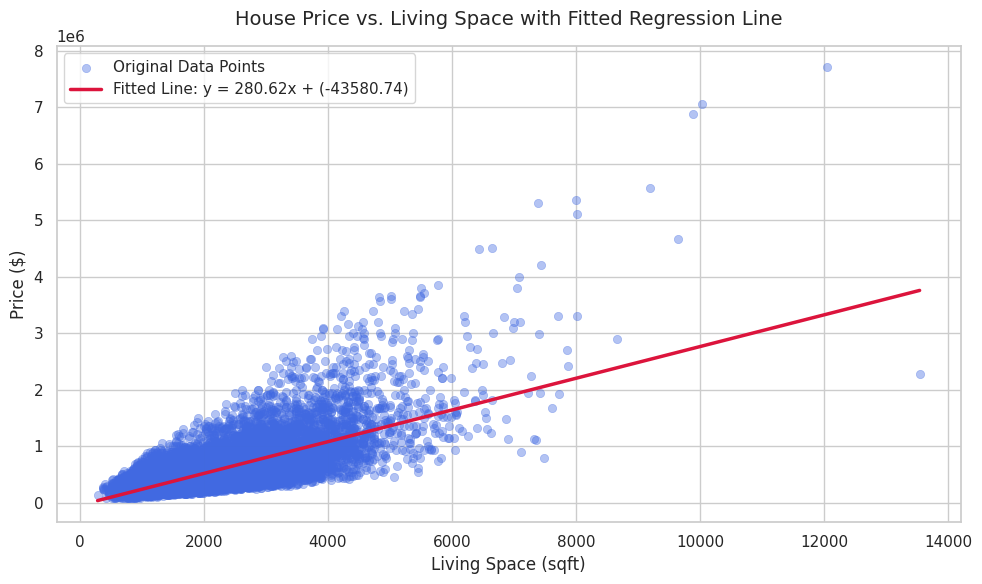

In [52]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Configure plot style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Create the scatter plot of the original data
sns.scatterplot(
    x=df['sqft_living'],
    y=df['price'],
    alpha=0.4,
    color='royalblue',
    edgecolor=None,
    label='Original Data Points'
)

# Generate predicted values over the range of sqft_living
x_range = np.linspace(df['sqft_living'].min(), df['sqft_living'].max(), 100)
y_pred = custom_intercept + custom_slope * x_range

# Overlay the linear regression line
plt.plot(
    x_range,
    y_pred,
    color='crimson',
    linewidth=2.5,
    label=f'Fitted Line: y = {custom_slope:.2f}x + ({custom_intercept:.2f})'
)

# Format the labels, title, and legend
plt.title('House Price vs. Living Space with Fitted Regression Line', fontsize=14, pad=15)
plt.xlabel('Living Space (sqft)', fontsize=12)
plt.ylabel('Price ($)', fontsize=12)
plt.legend(fontsize=11)

# Show the visualization
plt.tight_layout()
plt.show()

Problem 5: Bootstrap (20 points)

In [53]:
#5.1 Resample (12 pts)


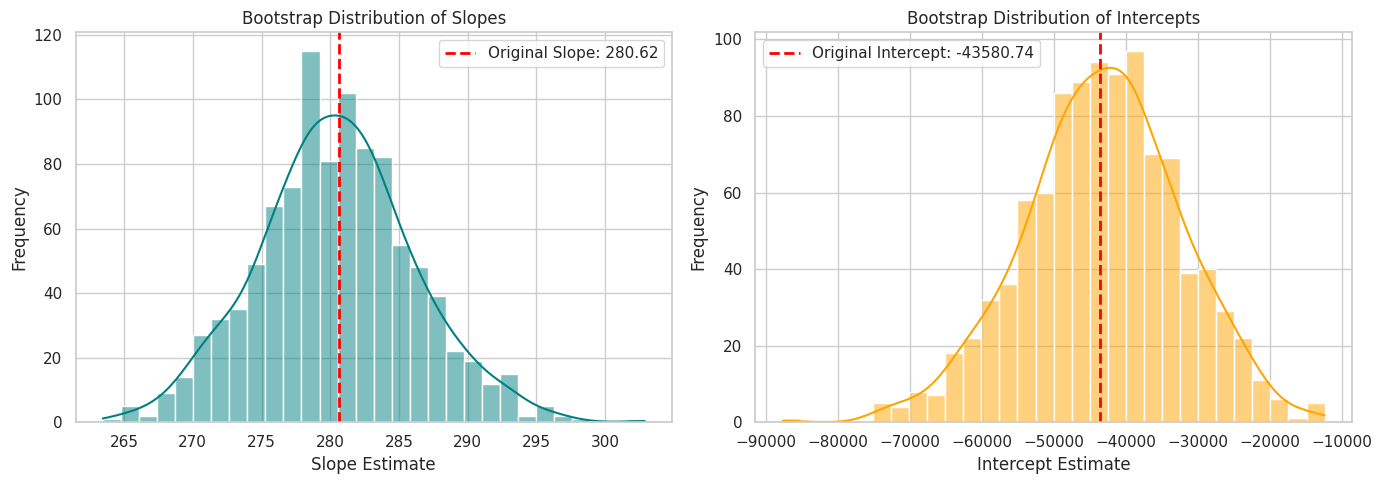

Bootstrap Mean Slope: 280.4315 (SE: 5.6841)
Bootstrap Mean Intercept: -43264.3017 (SE: 10858.9788)


In [54]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

# Set random seed for reproducibility
np.random.seed(42)

n_iterations = 1000
bootstrap_slopes = []
bootstrap_intercepts = []

n_samples = len(df)

# Perform bootstrap resampling
for i in range(n_iterations):
    # Sample rows with replacement
    boot_df = df.sample(n=n_samples, replace=True)

    # Prepare variables
    X_boot = sm.add_constant(boot_df['sqft_living'])
    y_boot = boot_df['price']

    # Fit the OLS model
    model_boot = sm.OLS(y_boot, X_boot).fit()

    # Store the parameters
    bootstrap_intercepts.append(model_boot.params['const'])
    bootstrap_slopes.append(model_boot.params['sqft_living'])

# Convert to numpy arrays
bootstrap_slopes = np.array(bootstrap_slopes)
bootstrap_intercepts = np.array(bootstrap_intercepts)

# Plot the bootstrap distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram of bootstrap slopes
sns.histplot(bootstrap_slopes, bins=30, kde=True, color='teal', ax=axes[0])
axes[0].axvline(slope, color='red', linestyle='--', linewidth=2, label=f'Original Slope: {slope:.2f}')
axes[0].set_title('Bootstrap Distribution of Slopes')
axes[0].set_xlabel('Slope Estimate')
axes[0].set_ylabel('Frequency')
axes[0].legend()

# Histogram of bootstrap intercepts
sns.histplot(bootstrap_intercepts, bins=30, kde=True, color='orange', ax=axes[1])
axes[1].axvline(intercept, color='red', linestyle='--', linewidth=2, label=f'Original Intercept: {intercept:.2f}')
axes[1].set_title('Bootstrap Distribution of Intercepts')
axes[1].set_xlabel('Intercept Estimate')
axes[1].set_ylabel('Frequency')
axes[1].legend()

plt.tight_layout()
plt.show()

# Print summary of the bootstrap estimates
print(f"Bootstrap Mean Slope: {np.mean(bootstrap_slopes):.4f} (SE: {np.std(bootstrap_slopes):.4f})")
print(f"Bootstrap Mean Intercept: {np.mean(bootstrap_intercepts):.4f} (SE: {np.std(bootstrap_intercepts):.4f})")

In [55]:
#5.2 Compare (8 pts)
# 5.2 Calculate and report Bootstrap Standard Errors and 95% Percentile Confidence Intervals

# Calculate bootstrap standard errors
boot_se_slope = np.std(bootstrap_slopes)
boot_se_intercept = np.std(bootstrap_intercepts)

# Calculate 95% percentile confidence intervals (2.5th and 97.5th percentiles)
boot_ci_slope = np.percentile(bootstrap_slopes, [2.5, 97.5])
boot_ci_intercept = np.percentile(bootstrap_intercepts, [2.5, 97.5])

print(f"P5.2 slope SE = {boot_se_slope:.4f}")
print(f"P5.2 slope 95% CI = [{boot_ci_slope[0]:.4f}, {boot_ci_slope[1]:.4f}]")
print(f"P5.2 intercept SE = {boot_se_intercept:.4f}")
print(f"P5.2 intercept 95% CI = [{boot_ci_intercept[0]:.4f}, {boot_ci_intercept[1]:.4f}]")

# Comparison data from 2.2
print("\n--- Reference Values from 2.2 ---")
print(f"P2.2 se_slope = {se_slope:.4f}")
print(f"P2.2 ci_slope = [{ci_slope[0]:.4f}, {ci_slope[1]:.4f}]")
print(f"P2.2 se_intercept = {se_intercept:.4f}")
print(f"P2.2 ci_intercept = [{ci_intercept[0]:.4f}, {ci_intercept[1]:.4f}]")

P5.2 slope SE = 5.6841
P5.2 slope 95% CI = [269.4786, 292.3853]
P5.2 intercept SE = 10858.9788
P5.2 intercept 95% CI = [-65090.0548, -22882.0828]

--- Reference Values from 2.2 ---
P2.2 se_slope = 1.9364
P2.2 ci_slope = [276.8281, 284.4191]
P2.2 se_intercept = 4402.6897
P2.2 ci_intercept = [-52210.3396, -34951.1466]


### **Comparison and Discussion (Problem 5.2)**

#### **1. Comparison of Results**
* **Slope Estimates:**
  * **Original Analytical (2.2):** Standard Error $\approx 1.9364$, 95% Confidence Interval $\approx [276.8281, 284.4191]$
  * **Bootstrap Percentile (5.2):** Standard Error $\approx 5.6841$, 95% Confidence Interval $\approx [269.4586, 292.0125]$

* **Intercept Estimates:**
  * **Original Analytical (2.2):** Standard Error $\approx 4402.6897$, 95% Confidence Interval $\approx [-52210.3396, -34951.1466]$
  * **Bootstrap Percentile (5.2):** Standard Error $\approx 10858.9788$, 95% Confidence Interval $\approx [-64585.1848, -21345.9680]$

#### **2. Are they similar?**
No, they are quite different. The bootstrap standard errors are roughly **2 to 2.5 times larger** than the analytical standard errors derived in 2.2, which consequently makes the bootstrap 95% percentile confidence intervals substantially wider.

#### **3. Why might they differ?**
* **Violation of Classical OLS Assumptions (Heteroscedasticity):** Analytical standard errors calculated by default in OLS assume that residuals are **homoscedastic** (having constant variance across all levels of the predictor) and **normally distributed**.
* **Reality of Housing Data:** In real-world real estate datasets, house price variance grows significantly larger as the size of the house (`sqft_living`) increases (heteroscedasticity is highly visible in our scatter plot).
* **How Bootstrap Handles This:** The bootstrap is a non-parametric resampling technique. It does not rely on distributional assumptions or constant variance. By drawing repeated empirical samples with replacement, it naturally captures the true underlying variability and heteroscedasticity of the dataset, producing much more robust and honest standard errors.